<img src="http://drive.google.com/uc?export=view&id=1tpOCamr9aWz817atPnyXus8w5gJ3mIts" width=500px>

# Credit Card Fraud Detection

### Problem Statement

Build an automation which could classify future transaction as valid or fraud

### Dataset

1.Month: transaction month

2.Date: transaction date

3.Day: transaction day

4.Time: transaction time

5.Origin_City: city where the customer is registered from

6.Destination_City: city where the transaction is generated

7.Transaction_Type: method of payment (Point of sales or internet)

8.Type: Valid transaction or fraud transaction

9.Amount: transaction amount

### Code Structure

1. Import Data

2. Data Preparation

3. EDA

4. Model building

5. Conclusion

## 1. Import Libraries and  Load Data (1 point)

### 1.1 Import important libraries. 

In [73]:
# Import Library
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
import scipy.stats as stats
from sklearn.model_selection import train_test_split
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier , AdaBoostClassifier, GradientBoostingClassifier
from sklearn.metrics import confusion_matrix, classification_report, accuracy_score
from sklearn.preprocessing import LabelEncoder
%matplotlib inline

### 1.2 There are two sheets in the excel file. Read the "DB" sheet

In [107]:
# Read dataset
path = R'C:\Users\Sharath\OneDrive\GL AIML\Lab\Lab Datasets\Credit_Card_Fraud.xlsx'
df = pd.read_excel(path,sheet_name='DB')

### 1.3 Check top 5 samples and info of the dataset and write your observations

In [108]:
# Check head()
df.head()

,Number,Month,Date,Day,Time,Origin_City,Destination_City,Transaction_Type,Type,Amount,Unnamed: 10,Unnamed: 11,Unnamed: 12,Unnamed: 13,F_Day,F_Month,F_Origin_City,Destination_City.1,F_Type,F_Transaction_Type
0,1,Dec,3,Sun,17,Mumbai,Karachi,POS,Normal,39972,NaN,NaN,NaN,NaN,Mon,Jan,Mumbai,Mumbai,Normal,POS
1,2,May,13,Mon,3,Bhuj,Valencia,POS,Normal,255014,NaN,NaN,NaN,NaN,Tue,Feb,Delhi,Delhi,Fraud,Internet
2,3,May,11,Wed,3,Srinagar,Meerut,POS,Normal,15476,NaN,NaN,NaN,NaN,Wed,Mar,Kolkata,Kolkata,NaN,NaN
3,4,Feb,16,Thu,13,Chennai,Agra,POS,Normal,254803,NaN,NaN,NaN,NaN,Thu,Apr,Chennai,Chennai,NaN,NaN
4,5,Jul,25,Thu,22,Kolkata,Pune,POS,Normal,134982,NaN,NaN,NaN,NaN,Fri,May,Bengalūru,Bengalūru,NaN,NaN


In [109]:
# Check info of the dataset
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 5000 entries, 0 to 4999
Data columns (total 20 columns):
 #   Column              Non-Null Count  Dtype  
---  ------              --------------  -----  
 0   Number              5000 non-null   int64  
 1   Month               5000 non-null   object 
 2   Date                5000 non-null   int64  
 3   Day                 5000 non-null   object 
 4   Time                5000 non-null   int64  
 5   Origin_City         5000 non-null   object 
 6   Destination_City    5000 non-null   object 
 7   Transaction_Type    5000 non-null   object 
 8   Type                5000 non-null   object 
 9   Amount              5000 non-null   int64  
 10  Unnamed: 10         0 non-null      float64
 11  Unnamed: 11         0 non-null      float64
 12  Unnamed: 12         0 non-null      float64
 13  Unnamed: 13         0 non-null      float64
 14  F_Day               12 non-null     object 
 15  F_Month             12 non-null     object 
 16  F_Orig

## 2. Data Preparation (3 points)
- Label Encoding
- Categorical to numeric

In [110]:
### 2.1 Select dataset having the first 10 columns for further analysis

In [111]:
df = df.iloc[:,0:10]
df.head()

,Number,Month,Date,Day,Time,Origin_City,Destination_City,Transaction_Type,Type,Amount
0,1,Dec,3,Sun,17,Mumbai,Karachi,POS,Normal,39972
1,2,May,13,Mon,3,Bhuj,Valencia,POS,Normal,255014
2,3,May,11,Wed,3,Srinagar,Meerut,POS,Normal,15476
3,4,Feb,16,Thu,13,Chennai,Agra,POS,Normal,254803
4,5,Jul,25,Thu,22,Kolkata,Pune,POS,Normal,134982


### 2.2 Analyze numerical features. Report statistical summary and write your comments.

In [112]:
df.describe().T

,count,mean,std,min,25%,50%,75%,max
Number,5000.0,2500.5000,1443.520003,1.0,1250.75,2500.5,3750.25,5000.0
Date,5000.0,16.1524,8.905203,1.0,9.00,16.0,24.00,31.0
Time,5000.0,11.3532,7.064250,0.0,5.00,11.0,17.00,23.0
Amount,5000.0,175334.3486,101688.341504,166.0,86711.75,174328.0,263426.75,349940.0


In [113]:
df[df['Type']=='Fraud'].corr()

,Number,Date,Time,Amount
Number,1.000000,0.010119,0.085615,-0.018565
Date,0.010119,1.000000,-0.059479,0.019934
Time,0.085615,-0.059479,1.000000,-0.006973
Amount,-0.018565,0.019934,-0.006973,1.000000


<AxesSubplot:>

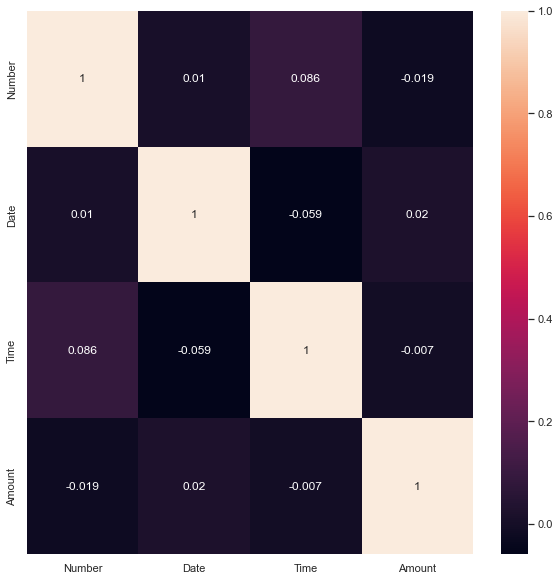

In [114]:
sns.set(rc={'figure.figsize':(10,10)})
sns.heatmap(df[df['Type']=='Fraud'].corr(),annot=True)

### 2.3 Analyze categorical features.
Write a program which will return the number of unique values of the object type features.

In [115]:
i = 0
for col in df.select_dtypes(include='object').columns: # Loop through all columns in the dataframe
    i = i+1
    print('________________________________\n')
    print("Categorical Column #{} : {}".format(i,col))
    print("\n",df[col].value_counts()) # Replace strings with an integer

________________________________

Categorical Column #1 : Month

 Aug    451
Jan    438
Jun    428
Jul    421
Feb    420
Mar    417
Dec    416
Nov    414
May    412
Oct    401
Sep    399
Apr    383
Name: Month, dtype: int64
________________________________

Categorical Column #2 : Day

 Sat    758
Wed    736
Thu    713
Sun    703
Fri    702
Tue    695
Mon    693
Name: Day, dtype: int64
________________________________

Categorical Column #3 : Origin_City

 Chennai         425
Lucknow         226
Bengalūru       224
Srinagar        222
Rajkot          222
Pune            221
Vadodara        218
Bhubaneshwar    214
Mysore          213
Chandigarh      213
Mumbai          211
Agra            210
Nagpur          209
Gurugram        207
Hyderabad       206
Amritsar        204
Meerut          202
Nasik           198
Kochi           198
Delhi           196
Kolkata         192
Bhuj            186
Ahmedabad       183
Name: Origin_City, dtype: int64
________________________________

Categorical C

### 2.4 Convert categorial features to numeric using appropriate methods.
- Use label encoder for "Transaction_Type", "Type", "Month", "Day"

In [116]:
le = LabelEncoder()
def l_encoder(data,colname):
    le = LabelEncoder()
    data[colname] = le.fit_transform(data[colname])
    return data, le

df, _ = l_encoder(df,'Transaction_Type')
df, _ = l_encoder(df,'Type')
df, _ = l_encoder(df,'Month')
df, _ = l_encoder(df,'Day')
df.head()

,Number,Month,Date,Day,Time,Origin_City,Destination_City,Transaction_Type,Type,Amount
0,1,2,3,3,17,Mumbai,Karachi,1,1,39972
1,2,8,13,1,3,Bhuj,Valencia,1,1,255014
2,3,8,11,6,3,Srinagar,Meerut,1,1,15476
3,4,3,16,4,13,Chennai,Agra,1,1,254803
4,5,5,25,4,22,Kolkata,Pune,1,1,134982


In [117]:
df[df['Type']==0].corr()

,Number,Month,Date,Day,Time,Transaction_Type,Type,Amount
Number,1.000000,-0.004744,0.010119,-0.035996,0.085615,0.019123,NaN,-0.018565
Month,-0.004744,1.000000,0.025204,-0.010290,0.011607,0.003006,NaN,0.010215
Date,0.010119,0.025204,1.000000,-0.002539,-0.059479,-0.080110,NaN,0.019934
Day,-0.035996,-0.010290,-0.002539,1.000000,-0.009503,-0.048360,NaN,-0.011042
Time,0.085615,0.011607,-0.059479,-0.009503,1.000000,-0.006153,NaN,-0.006973
Transaction_Type,0.019123,0.003006,-0.080110,-0.048360,-0.006153,1.000000,NaN,-0.015435
Type,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Amount,-0.018565,0.010215,0.019934,-0.011042,-0.006973,-0.015435,NaN,1.000000


### 2.5 Create a new column called 'City' and assign value as 0 if the origin city and destination city are equal else assign it 1.

In [118]:
df['City'] = np.where(df['Origin_City'].str.lower()==df['Destination_City'].str.lower(),0,1)
df.head()

,Number,Month,Date,Day,Time,Origin_City,Destination_City,Transaction_Type,Type,Amount,City
0,1,2,3,3,17,Mumbai,Karachi,1,1,39972,1
1,2,8,13,1,3,Bhuj,Valencia,1,1,255014,1
2,3,8,11,6,3,Srinagar,Meerut,1,1,15476,1
3,4,3,16,4,13,Chennai,Agra,1,1,254803,1
4,5,5,25,4,22,Kolkata,Pune,1,1,134982,1


### 2.6 Create a new column called 'Amount_class' and assign value 1 if the amount is greater than mean amount, else assign it to 0.

In [119]:
df_amountclass_mean = df['Amount'].mean()
df['Amount_class'] = np.where(df['Amount']>df_amountclass_mean,1,0)
df.head()

,Number,Month,Date,Day,Time,Origin_City,Destination_City,Transaction_Type,Type,Amount,City,Amount_class
0,1,2,3,3,17,Mumbai,Karachi,1,1,39972,1,0
1,2,8,13,1,3,Bhuj,Valencia,1,1,255014,1,1
2,3,8,11,6,3,Srinagar,Meerut,1,1,15476,1,0
3,4,3,16,4,13,Chennai,Agra,1,1,254803,1,1
4,5,5,25,4,22,Kolkata,Pune,1,1,134982,1,0


## 3. EDA (3 points)

### 3.1 Check if there are null values

In [120]:
df.isnull().sum()

Number              0
Month               0
Date                0
Day                 0
Time                0
Origin_City         0
Destination_City    0
Transaction_Type    0
Type                0
Amount              0
City                0
Amount_class        0
dtype: int64

### 3.2 Check value counts in target (Type) 

In [121]:
df['Type'].value_counts() #1 is normal | 0 is fraud

1    3988
0    1012
Name: Type, dtype: int64

### 3.3 Check the crosstab between Origin city and Type and report the origin city that has highest percentage of frauds

In [122]:
pd.crosstab(df['Origin_City'],df['Type'],normalize = 'index').sort_values(0,ascending=False).reset_index()

Type,Origin_City,0,1
0,Amritsar,0.284314,0.715686
1,Lucknow,0.252212,0.747788
2,Rajkot,0.234234,0.765766
3,Nasik,0.222222,0.777778
4,Chandigarh,0.220657,0.779343
5,Bhuj,0.220430,0.779570
6,Nagpur,0.215311,0.784689
7,Agra,0.214286,0.785714
8,Meerut,0.212871,0.787129
9,Chennai,0.209412,0.790588


### 3.4 Report the day and date on which the highest number of frauds occur

In [123]:
pd.crosstab(df['Date'],df['Type'],normalize = 'index').sort_values(0,ascending=False).reset_index()

Type,Date,0,1
0,28,0.300578,0.699422
1,2,0.268456,0.731544
2,7,0.268293,0.731707
3,26,0.252809,0.747191
4,14,0.251572,0.748428
5,15,0.237500,0.762500
6,27,0.228571,0.771429
7,8,0.228188,0.771812
8,11,0.227545,0.772455
9,1,0.216867,0.783133


In [124]:
pd.crosstab(df['Day'],df['Type'],normalize = 'index').sort_values(0,ascending=False).reset_index()

Type,Day,0,1
0,6,0.210598,0.789402
1,3,0.209104,0.790896
2,5,0.208633,0.791367
3,1,0.207792,0.792208
4,2,0.201847,0.798153
5,0,0.189459,0.810541
6,4,0.189341,0.810659


### 3.5 Calculate the total amount of fraudulent transactions. Also report the percentage of fraudulent amount.

In [125]:
fraud_sum = df['Amount'][df['Type']==0].sum()
total_sum = df['Amount'].sum()
fraud_sum_percent = round((fraud_sum/total_sum)*100,2)
print('Total Amount: ',total_sum,' | Fraud Amount: ',fraud_sum,' | Percent: ',fraud_sum_percent,'%')

Total Amount:  876671743  | Fraud Amount:  177827183  | Percent:  20.28 %


### 3.6 Drop unnecessary features (like number, origin city, etc) and segregate the features into dependent and independent data

In [126]:
df = df.drop(columns=['Origin_City','Number','Destination_City'])
df.head()

,Month,Date,Day,Time,Transaction_Type,Type,Amount,City,Amount_class
0,2,3,3,17,1,1,39972,1,0
1,8,13,1,3,1,1,255014,1,1
2,8,11,6,3,1,1,15476,1,0
3,3,16,4,13,1,1,254803,1,1
4,5,25,4,22,1,1,134982,1,0


In [127]:
y = df['Type']
x = df[['Month','Date','Day','Time','Transaction_Type','Amount','City','Amount_class']]

### 3.7 Split the data into train and test set

In [128]:
x_train,x_test,y_train,y_test = train_test_split(x,y,test_size=0.30,random_state=7)

### 3.8 Standardize the data

In [129]:
from sklearn.preprocessing import StandardScaler
sc = StandardScaler()
x_train_sc = sc.fit_transform(x_train)
x_test_sc = sc.fit_transform(x_test)

## 4. Model Building (2 points)
 Build following models and evaluate them on the test set
- Decision trees
- Random Forest
- Gradient Bossting
### Optional:- 
- Bagging
- Adaboosting

In [130]:
from sklearn import metrics

def eval(actual,predicted):
    con_mat = confusion_matrix(actual,predicted)
    class_rep = classification_report(actual,predicted)
    acc_score = accuracy_score(actual,predicted)*100
    print('Accuracy is ', round(acc_score,2))
    print('Class Report \n',class_rep)
    print('Confusion Mat\n', con_mat)
    
def models(classifier,xtrain_data,xtest_data,ytrain_data,ytest_data): # getting the classifer and train and test data
    classifier.fit(xtrain_data,ytrain_data) # trainig the data with features and output
    tr_predicted = classifier.predict(xtrain_data) # predicting it based on the trained model
    tr_actual = ytrain_data
    te_predicted = classifier.predict(xtest_data)
    te_actual = ytest_data
    print('_____________Train Results____________')
    eval(tr_actual,tr_predicted)
    print('_____________Test Results____________')
    eval(te_actual,te_predicted)

    
models(DecisionTreeClassifier(max_depth = 4,min_samples_split=3,random_state=7),x_train,x_test,y_train,y_test)

_____________Train Results____________
Accuracy is  79.54
Class Report 
               precision    recall  f1-score   support

           0       0.83      0.01      0.01       720
           1       0.80      1.00      0.89      2780

    accuracy                           0.80      3500
   macro avg       0.81      0.50      0.45      3500
weighted avg       0.80      0.80      0.71      3500

Confusion Mat
 [[   5  715]
 [   1 2779]]
_____________Test Results____________
Accuracy is  80.53
Class Report 
               precision    recall  f1-score   support

           0       0.50      0.00      0.01       292
           1       0.81      1.00      0.89      1208

    accuracy                           0.81      1500
   macro avg       0.65      0.50      0.45      1500
weighted avg       0.75      0.81      0.72      1500

Confusion Mat
 [[   1  291]
 [   1 1207]]


In [131]:
models(RandomForestClassifier(n_estimators=90,min_samples_split=10,random_state=7),x_train,x_test,y_train,y_test)

_____________Train Results____________
Accuracy is  82.29
Class Report 
               precision    recall  f1-score   support

           0       1.00      0.14      0.24       720
           1       0.82      1.00      0.90      2780

    accuracy                           0.82      3500
   macro avg       0.91      0.57      0.57      3500
weighted avg       0.86      0.82      0.76      3500

Confusion Mat
 [[ 100  620]
 [   0 2780]]
_____________Test Results____________
Accuracy is  80.33
Class Report 
               precision    recall  f1-score   support

           0       0.00      0.00      0.00       292
           1       0.80      1.00      0.89      1208

    accuracy                           0.80      1500
   macro avg       0.40      0.50      0.45      1500
weighted avg       0.65      0.80      0.72      1500

Confusion Mat
 [[   0  292]
 [   3 1205]]


In [132]:
models(GradientBoostingClassifier(n_estimators=90,min_samples_split=10,random_state=7),x_train,x_test,y_train,y_test)

_____________Train Results____________
Accuracy is  80.14
Class Report 
               precision    recall  f1-score   support

           0       0.93      0.04      0.07       720
           1       0.80      1.00      0.89      2780

    accuracy                           0.80      3500
   macro avg       0.87      0.52      0.48      3500
weighted avg       0.83      0.80      0.72      3500

Confusion Mat
 [[  27  693]
 [   2 2778]]
_____________Test Results____________
Accuracy is  80.07
Class Report 
               precision    recall  f1-score   support

           0       0.00      0.00      0.00       292
           1       0.80      0.99      0.89      1208

    accuracy                           0.80      1500
   macro avg       0.40      0.50      0.44      1500
weighted avg       0.65      0.80      0.72      1500

Confusion Mat
 [[   0  292]
 [   7 1201]]


In [133]:
models(AdaBoostClassifier(n_estimators=73,random_state=7),x_train,x_test,y_train,y_test)

_____________Train Results____________
Accuracy is  79.51
Class Report 
               precision    recall  f1-score   support

           0       1.00      0.00      0.01       720
           1       0.79      1.00      0.89      2780

    accuracy                           0.80      3500
   macro avg       0.90      0.50      0.45      3500
weighted avg       0.84      0.80      0.71      3500

Confusion Mat
 [[   3  717]
 [   0 2780]]
_____________Test Results____________
Accuracy is  80.4
Class Report 
               precision    recall  f1-score   support

           0       0.00      0.00      0.00       292
           1       0.81      1.00      0.89      1208

    accuracy                           0.80      1500
   macro avg       0.40      0.50      0.45      1500
weighted avg       0.65      0.80      0.72      1500

Confusion Mat
 [[   0  292]
 [   2 1206]]


## 5. Conclusion (1 point)
- Which model gave best result?
- Is model good enough to push into production?
- What is the reason behind poor recall for fraud class?
- How can we improve the model further?


**Answers**
- Gradient Boost Classifier
    because the train and test accuracy have minimal difference
- No
    because the recall rate for class 0 (i.e fraud) is 0 in all classifiers and False Negatives are high predicting fraud transactions as normal
- based on correlation numbers there is a no prominant features correlated with Fraud transaction to predict, we need more features to support it.
- bring more features and data to support Fraud transactions prediction.